# Khai phá luật kết hợp bằng thuật toán Apriori
## Phân tích dịch vụ viễn thông và trả lời 6 câu hỏi

**Dữ liệu:** IBM Telco Customer Churn, gồm nhân khẩu học, dịch vụ, hợp đồng, thanh toán và nhãn rời mạng.

**Mục tiêu**
1. Tìm tổ hợp dịch vụ thường được dùng cùng nhau và tính P(B|A).
2. Tìm tổ hợp đặc điểm gắn với rời mạng hoặc ở lại.
3. Phân tích gói dịch vụ theo nhân khẩu học và tạo gợi ý bổ sung dịch vụ.

**Quy trình:** làm sạch → biểu diễn giao dịch → Apriori → sinh luật → kiểm chứng → trả lời 6 câu hỏi → xuất bảng và biểu đồ.


## 1. Thiết lập môi trường

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
from IPython.display import display

from telco_arm import Settings, apriori, generate_rules
from telco_arm import analysis, visualization as viz
from telco_arm.data_loader import load_dataset, load_raw
from telco_arm.pipeline import PROFILE_COLUMNS, SERVICE_ITEMS, export_figures, export_tables, run
from telco_arm.preprocessing import build_transactions, one_hot_encode, usage_items

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
viz.apply_theme()
settings = Settings()
settings

Settings(paths=Paths(raw_data=WindowsPath('C:/Users/ADMIN/OneDrive/Desktop/KPDL/data/raw/telco_customer_churn.csv'), output_dir=WindowsPath('C:/Users/ADMIN/OneDrive/Desktop/KPDL/outputs')), features=FeatureSpec(id_column='customerID', target_column='Churn', tenure_bins=(-1, 12, 24, 48, 72), tenure_labels=('0-12m', '13-24m', '25-48m', '49-72m'), charge_labels=('Low', 'Medium', 'High'), demographic_columns=('gender', 'SeniorCitizen', 'Partner', 'Dependents'), binary_columns=('gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling'), categorical_columns=('InternetService', 'Contract', 'PaymentMethod'), addon_columns=('MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies'), not_applicable_values=('No internet service', 'No phone service')), mining=MiningParams(min_support=0.1, min_confidence=0.7, min_lift=1.2, max_len=4), questions=QuestionParams(demographic_support=0.02, demographic_confidence=0.

## 2. Đọc và làm sạch dữ liệu

In [2]:
raw = load_raw(settings.paths.raw_data)
print(f"Raw shape: {raw.shape}")
raw.head()

Raw shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
quality = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "unique": raw.nunique(),
    "blank_or_null": raw.isna().sum() + raw.apply(lambda s: s.astype(str).str.strip().eq("").sum()),
})
quality

,dtype,unique,blank_or_null
customerID,str,7043,0
gender,str,2,0
SeniorCitizen,int64,2,0
Partner,str,2,0
Dependents,str,2,0
tenure,int64,73,0
PhoneService,str,2,0
MultipleLines,str,3,0
InternetService,str,3,0
OnlineSecurity,str,3,0


`TotalCharges` lưu dạng chuỗi và có 11 giá trị rỗng (khách hàng mới, `tenure = 0`) → chuyển sang số và loại bỏ. `SeniorCitizen` được chuẩn hoá về `Yes/No` cho đồng nhất với các cột nhị phân khác.

In [4]:
customers = load_dataset(settings.paths.raw_data, settings.features)
churn_rate = (customers["Churn"] == "Yes").mean()
print(f"Clean shape: {customers.shape} | Churn rate: {churn_rate:.2%}")

Clean shape: (7032, 21) | Churn rate: 26.58%


## 3. Khám phá dữ liệu: tỷ lệ rời mạng theo từng thuộc tính

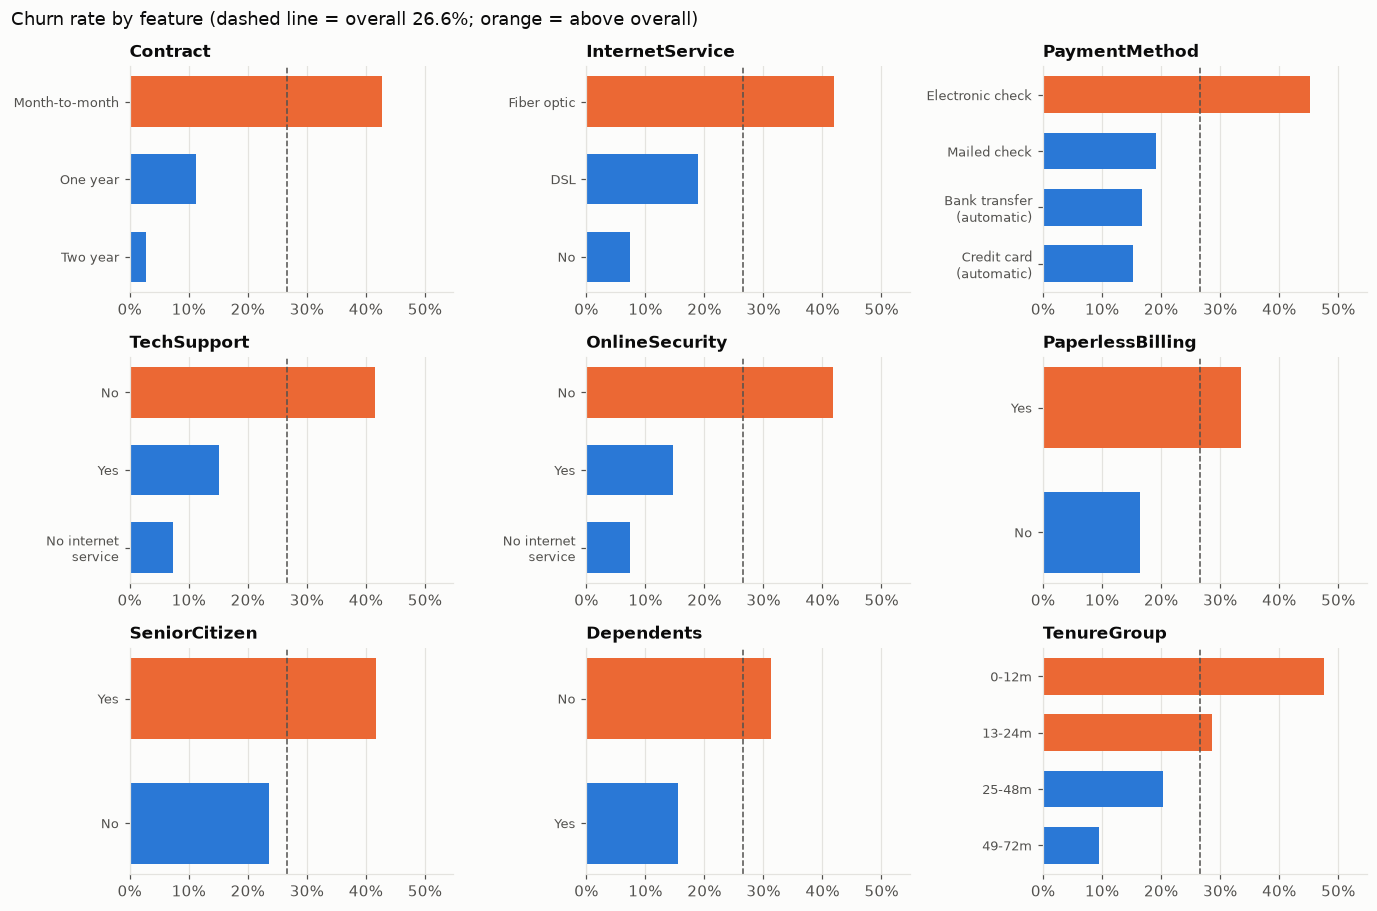

In [5]:
result = run(settings)
rates = analysis.churn_rate_by(result.customers, PROFILE_COLUMNS)
viz.plot_churn_rate_by_feature(rates, result.churn_rate);

In [6]:
rates.sort_values("churn_rate", ascending=False).head(10).style.format({"churn_rate": "{:.1%}"}).hide(axis="index")

feature,value,customers,churn_rate
TenureGroup,0-12m,2175,47.7%
PaymentMethod,Electronic check,2365,45.3%
Contract,Month-to-month,3875,42.7%
InternetService,Fiber optic,3096,41.9%
OnlineSecurity,No,3497,41.8%
SeniorCitizen,Yes,1142,41.7%
TechSupport,No,3472,41.6%
PaperlessBilling,Yes,4168,33.6%
Dependents,No,4933,31.3%
TenureGroup,13-24m,1024,28.7%


## 4. Biểu diễn dữ liệu dạng giao dịch

Apriori làm việc trên **giao dịch** (tập item). Mỗi khách hàng là một giao dịch, mỗi item có dạng `Thuộc_tính=Giá_trị`.

| Nhóm | Xử lý |
|---|---|
| Nhị phân & phân loại | Giữ nguyên giá trị (`Contract=Two year`, `Partner=Yes`, …) |
| `tenure` | Chia nhóm theo kỳ hợp đồng: `0-12m`, `13-24m`, `25-48m`, `49-72m` |
| `MonthlyCharges`, `TotalCharges` | Chia 3 phân vị đều: `Low`, `Medium`, `High` |
| `No internet service`, `No phone service` | Loại bỏ — đã được thể hiện qua `InternetService=No` / `PhoneService=No`, giữ lại sẽ sinh luật hiển nhiên |

In [7]:
for basket in result.transactions[:3]:
    print(sorted(basket), end="\n\n")
print(f"Transactions: {len(result.transactions):,} | Distinct items: {result.onehot.shape[1]}")

['Churn=No', 'Contract=Month-to-month', 'Dependents=No', 'DeviceProtection=No', 'InternetService=DSL', 'MonthlyCharges=Low', 'OnlineBackup=Yes', 'OnlineSecurity=No', 'PaperlessBilling=Yes', 'Partner=Yes', 'PaymentMethod=Electronic check', 'PhoneService=No', 'SeniorCitizen=No', 'StreamingMovies=No', 'StreamingTV=No', 'TechSupport=No', 'TenureGroup=0-12m', 'TotalCharges=Low', 'gender=Female']

['Churn=No', 'Contract=One year', 'Dependents=No', 'DeviceProtection=Yes', 'InternetService=DSL', 'MonthlyCharges=Medium', 'MultipleLines=No', 'OnlineBackup=No', 'OnlineSecurity=Yes', 'PaperlessBilling=No', 'Partner=No', 'PaymentMethod=Mailed check', 'PhoneService=Yes', 'SeniorCitizen=No', 'StreamingMovies=No', 'StreamingTV=No', 'TechSupport=No', 'TenureGroup=25-48m', 'TotalCharges=Medium', 'gender=Male']

['Churn=Yes', 'Contract=Month-to-month', 'Dependents=No', 'DeviceProtection=No', 'InternetService=DSL', 'MonthlyCharges=Medium', 'MultipleLines=No', 'OnlineBackup=Yes', 'OnlineSecurity=Yes', 'Pap

In [8]:
result.onehot.head()

,Churn=No,Churn=Yes,Contract=Month-to-month,Contract=One year,Contract=Two year,Dependents=No,Dependents=Yes,DeviceProtection=No,DeviceProtection=Yes,InternetService=DSL,...,TechSupport=Yes,TenureGroup=0-12m,TenureGroup=13-24m,TenureGroup=25-48m,TenureGroup=49-72m,TotalCharges=High,TotalCharges=Low,TotalCharges=Medium,gender=Female,gender=Male
0,True,False,True,False,False,True,False,True,False,True,...,False,True,False,False,False,False,True,False,True,False
1,True,False,False,True,False,True,False,False,True,True,...,False,False,False,True,False,False,False,True,False,True
2,False,True,True,False,False,True,False,True,False,True,...,False,True,False,False,False,False,True,False,False,True
3,True,False,False,True,False,True,False,False,True,True,...,True,False,False,True,False,False,False,True,False,True
4,False,True,True,False,False,True,False,True,False,False,...,False,True,False,False,False,False,True,False,True,False


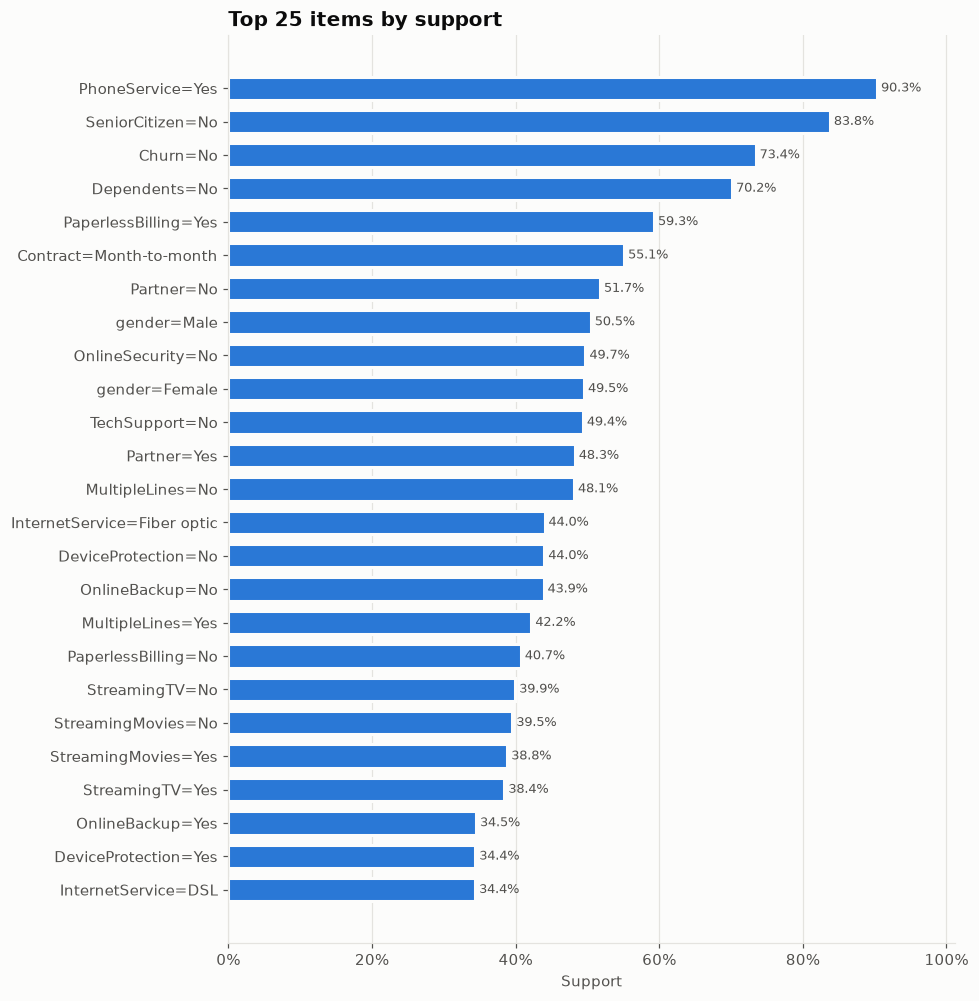

In [9]:
viz.plot_item_support(analysis.item_support(result.onehot), top_n=25);

## 5. Thuật toán Apriori

Cài đặt trong `src/telco_arm/apriori.py`:

1. Đếm support từng item và giữ các item đạt `min_support`.
2. Nối hai tập k−1 có chung k−2 phần tử đầu để tạo ứng viên k.
3. Loại ứng viên nếu có tập con k−1 không phổ biến.
4. Đếm support bằng phép AND vector boolean của tiền tố và item cuối.
5. Lặp đến khi không còn tập phổ biến hoặc đạt `max_len`.

Phần dịch vụ chỉ gồm `PhoneService=Yes`, Internet DSL/Fiber optic và các tiện ích `=Yes`. Nhân khẩu học, hợp đồng, thanh toán, cước và Churn chỉ tham gia các phân tích tương ứng, không trộn vào luật đồng sử dụng dịch vụ.


In [10]:
behavior = usage_items(result.onehot, settings.features, exclude=settings.target_items)
itemsets = apriori(behavior, settings.mining.min_support, settings.mining.max_len)
display(analysis.itemset_length_summary(itemsets))
analysis.readable_itemsets(itemsets).query("length >= 3").head(10)

,length,count,max_support,mean_support
0,1,10,0.9033,0.4147
1,2,43,0.4403,0.2117
2,3,65,0.2756,0.1494
3,4,33,0.1863,0.1278


,support,itemsets,length
53,0.2756,"InternetService=Fiber optic, MultipleLines=Yes, PhoneService=Yes",3
54,0.2490,"InternetService=Fiber optic, PhoneService=Yes, StreamingMovies=Yes",3
55,0.2489,"InternetService=Fiber optic, PhoneService=Yes, StreamingTV=Yes",3
56,0.2473,"PhoneService=Yes, StreamingMovies=Yes, StreamingTV=Yes",3
57,0.2263,"MultipleLines=Yes, PhoneService=Yes, StreamingMovies=Yes",3
58,0.2241,"MultipleLines=Yes, PhoneService=Yes, StreamingTV=Yes",3
59,0.2002,"DeviceProtection=Yes, PhoneService=Yes, StreamingMovies=Yes",3
60,0.1982,"DeviceProtection=Yes, PhoneService=Yes, StreamingTV=Yes",3
61,0.1930,"DeviceProtection=Yes, InternetService=Fiber optic, PhoneService=Yes",3
62,0.1930,"MultipleLines=Yes, OnlineBackup=Yes, PhoneService=Yes",3


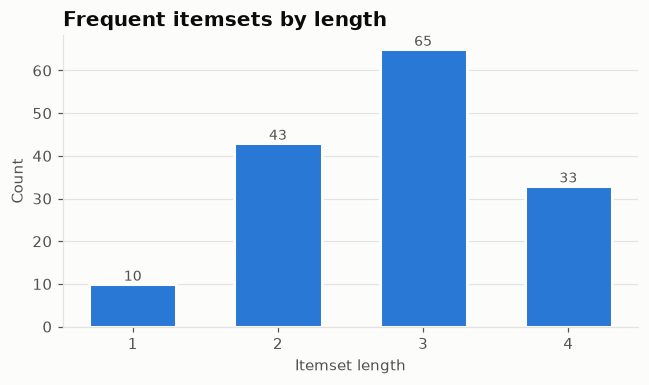

In [11]:
viz.plot_itemset_lengths(analysis.itemset_length_summary(itemsets));

### 5.1. Kiểm chứng tính đúng đắn với `mlxtend`

In [12]:
%%time
from mlxtend.frequent_patterns import apriori as mlxtend_apriori

reference = mlxtend_apriori(behavior, min_support=settings.mining.min_support,
                          use_colnames=True, max_len=settings.mining.max_len)
ours = dict(zip(itemsets['itemsets'], itemsets['support'].round(12)))
theirs = dict(zip(reference['itemsets'], reference['support'].round(12)))
assert ours == theirs, 'Apriori results differ from mlxtend'
print(f'Own: {len(ours):,} itemsets | mlxtend: {len(theirs):,} itemsets | identical: {ours == theirs}')


Own: 151 itemsets | mlxtend: 151 itemsets | identical: True
CPU times: total: 46.9 ms
Wall time: 117 ms


### 5.2. Độ nhạy theo ngưỡng `min_support`

,min_support,itemsets,rules,seconds
0,0.050,316,260,0.022
1,0.075,229,197,0.016
2,0.100,151,144,0.014
3,0.150,73,51,0.010
4,0.200,34,13,0.006
5,0.250,19,5,0.004
6,0.300,14,2,0.004


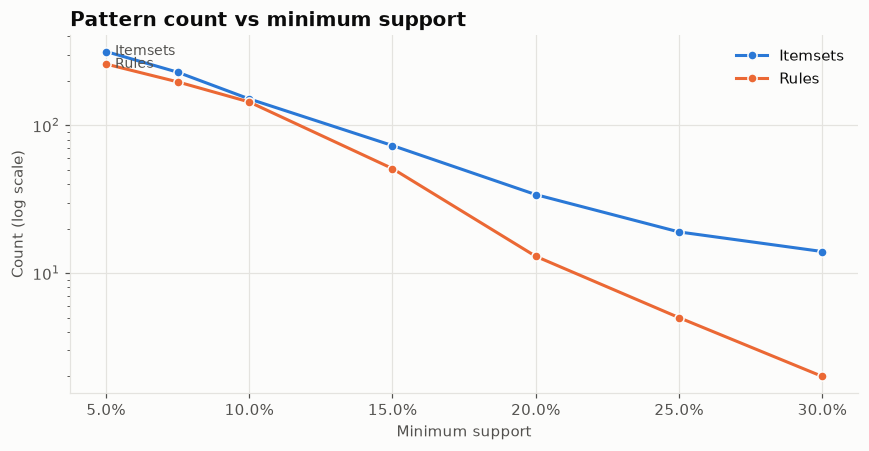

In [13]:
sensitivity = analysis.support_sensitivity(
    behavior, supports=[0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30],
    min_confidence=settings.mining.min_confidence, max_len=settings.mining.max_len,
)
display(sensitivity)
viz.plot_support_sensitivity(sensitivity);

Giảm ngưỡng support thường làm tăng số tập phổ biến và số luật. Bảng độ nhạy ở trên thể hiện kết quả đo trực tiếp cho dữ liệu hiện tại.

## 6. Luật đồng sử dụng dịch vụ

- **Support** = P(X ∪ Y).
- **Confidence** = P(Y | X).
- **Lift** = Confidence / P(Y), lớn hơn 1 khi đồng xuất hiện nhiều hơn mức độc lập.
- **Leverage** = P(X ∪ Y) − P(X)P(Y).
- **Conviction** = (1 − P(Y)) / (1 − Confidence).

Các tỷ lệ mô tả đồng sử dụng trên dữ liệu khai phá, chưa phải xác suất mua thêm trong tương lai.


In [14]:
service_rules = generate_rules(itemsets, settings.mining.min_confidence, settings.mining.min_lift)
print(f"{len(service_rules):,} rules (confidence ≥ {settings.mining.min_confidence:.0%}, lift ≥ {settings.mining.min_lift})")
analysis.readable_rules(service_rules).head(15)

109 rules (confidence ≥ 70%, lift ≥ 1.2)


,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{MultipleLines=Yes, StreamingTV=Yes} → {PhoneService=Yes, StreamingMovies=Yes}","MultipleLines=Yes, StreamingTV=Yes","PhoneService=Yes, StreamingMovies=Yes",2,0.1719,0.7671,2.2172,0.0944,2.8085
1,"{MultipleLines=Yes, StreamingMovies=Yes} → {PhoneService=Yes, StreamingTV=Yes}","MultipleLines=Yes, StreamingMovies=Yes","PhoneService=Yes, StreamingTV=Yes",2,0.1719,0.7599,2.2081,0.0941,2.7316
2,"{InternetService=Fiber optic, StreamingMovies=Yes} → {PhoneService=Yes, StreamingTV=Yes}","InternetService=Fiber optic, StreamingMovies=Yes","PhoneService=Yes, StreamingTV=Yes",2,0.1863,0.7481,2.1739,0.1006,2.6041
3,"{StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes} → {DeviceProtection=Yes}","StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes",DeviceProtection=Yes,3,0.1003,0.7468,2.1719,0.0541,2.5916
4,"{InternetService=Fiber optic, StreamingTV=Yes} → {PhoneService=Yes, StreamingMovies=Yes}","InternetService=Fiber optic, StreamingTV=Yes","PhoneService=Yes, StreamingMovies=Yes",2,0.1863,0.7486,2.1636,0.1002,2.6012
5,"{DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes",StreamingMovies=Yes,3,0.1003,0.8383,2.1585,0.0538,3.7822
6,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes",StreamingTV=Yes,3,0.1173,0.8291,2.1571,0.0629,3.6032
7,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes",StreamingTV=Yes,3,0.1139,0.8283,2.1550,0.0610,3.5861
8,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes",StreamingMovies=Yes,3,0.1173,0.8350,2.1501,0.0628,3.7073
9,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes",StreamingMovies=Yes,3,0.1139,0.8301,2.1373,0.0606,3.5989


In [15]:
analysis.readable_rules(service_rules.loc[
    service_rules['consequents'].map(len) == 1
]).head(15)


,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes} → {DeviceProtection=Yes}","StreamingMovies=Yes, StreamingTV=Yes, TechSupport=Yes",DeviceProtection=Yes,3,0.1003,0.7468,2.1719,0.0541,2.5916
1,"{DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, StreamingTV=Yes, TechSupport=Yes",StreamingMovies=Yes,3,0.1003,0.8383,2.1585,0.0538,3.7822
2,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingMovies=Yes",StreamingTV=Yes,3,0.1173,0.8291,2.1571,0.0629,3.6032
3,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingMovies=Yes",StreamingTV=Yes,3,0.1139,0.8283,2.1550,0.0610,3.5861
4,"{DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, MultipleLines=Yes, StreamingTV=Yes",StreamingMovies=Yes,3,0.1173,0.8350,2.1501,0.0628,3.7073
5,"{DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, InternetService=Fiber optic, StreamingTV=Yes",StreamingMovies=Yes,3,0.1139,0.8301,2.1373,0.0606,3.5989
6,"{DeviceProtection=Yes, StreamingMovies=Yes, TechSupport=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, StreamingMovies=Yes, TechSupport=Yes",StreamingTV=Yes,3,0.1003,0.8150,2.1203,0.0530,3.3282
7,"{DeviceProtection=Yes, OnlineBackup=Yes, StreamingMovies=Yes} → {StreamingTV=Yes}","DeviceProtection=Yes, OnlineBackup=Yes, StreamingMovies=Yes",StreamingTV=Yes,3,0.1052,0.8096,2.1063,0.0553,3.2337
8,"{DeviceProtection=Yes, OnlineBackup=Yes, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, OnlineBackup=Yes, StreamingTV=Yes",StreamingMovies=Yes,3,0.1052,0.8159,2.1008,0.0551,3.3219
9,"{DeviceProtection=Yes, StreamingTV=Yes} → {StreamingMovies=Yes}","DeviceProtection=Yes, StreamingTV=Yes",StreamingMovies=Yes,2,0.1782,0.8017,2.0642,0.0919,3.0838


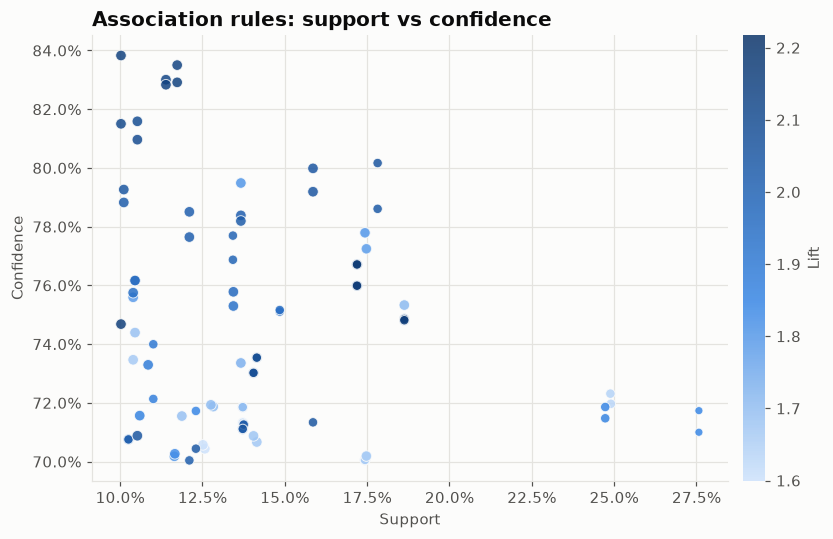

In [16]:
viz.plot_rules_scatter(service_rules);

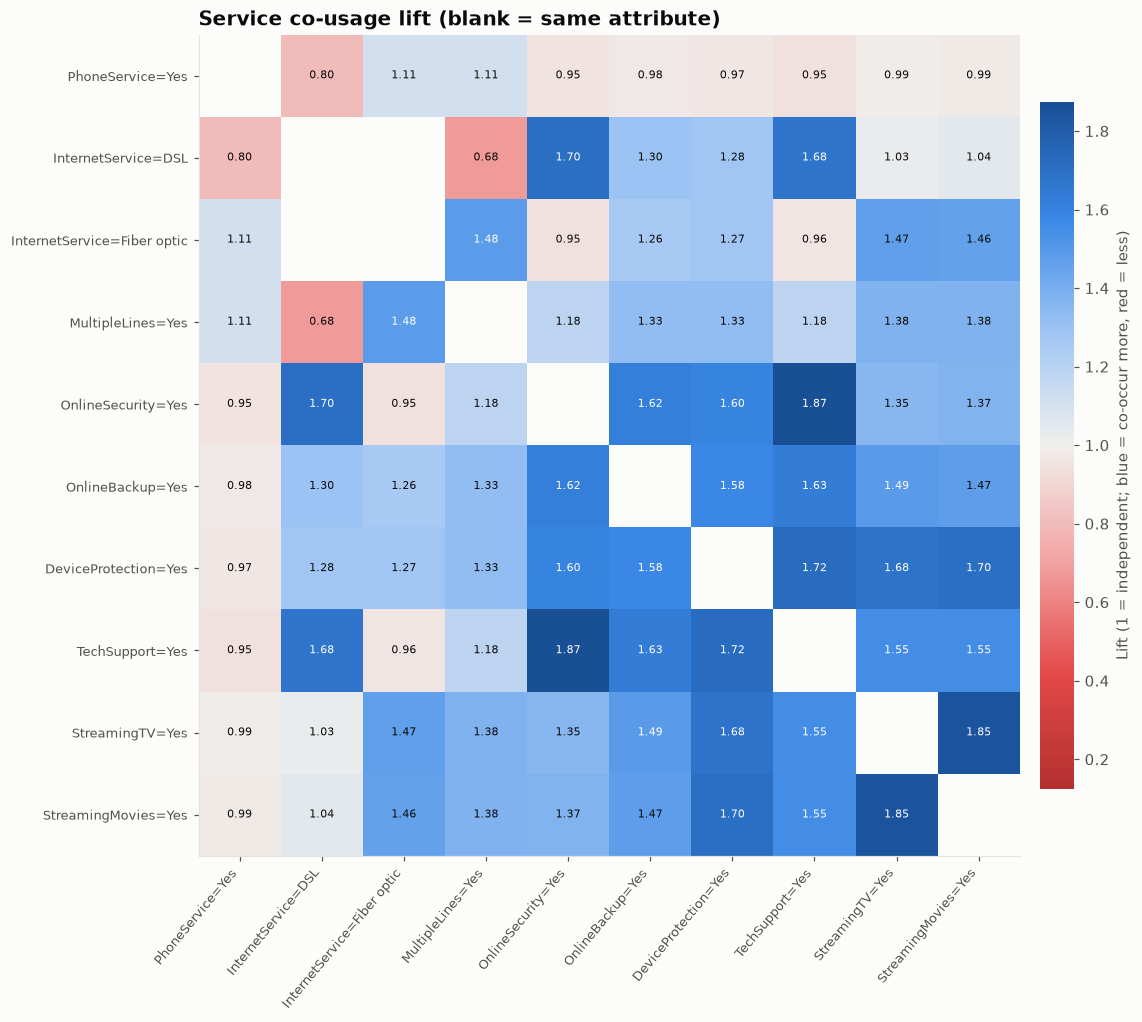

In [17]:
viz.plot_lift_matrix(analysis.pairwise_lift(result.onehot, SERVICE_ITEMS), title="Service co-usage lift");

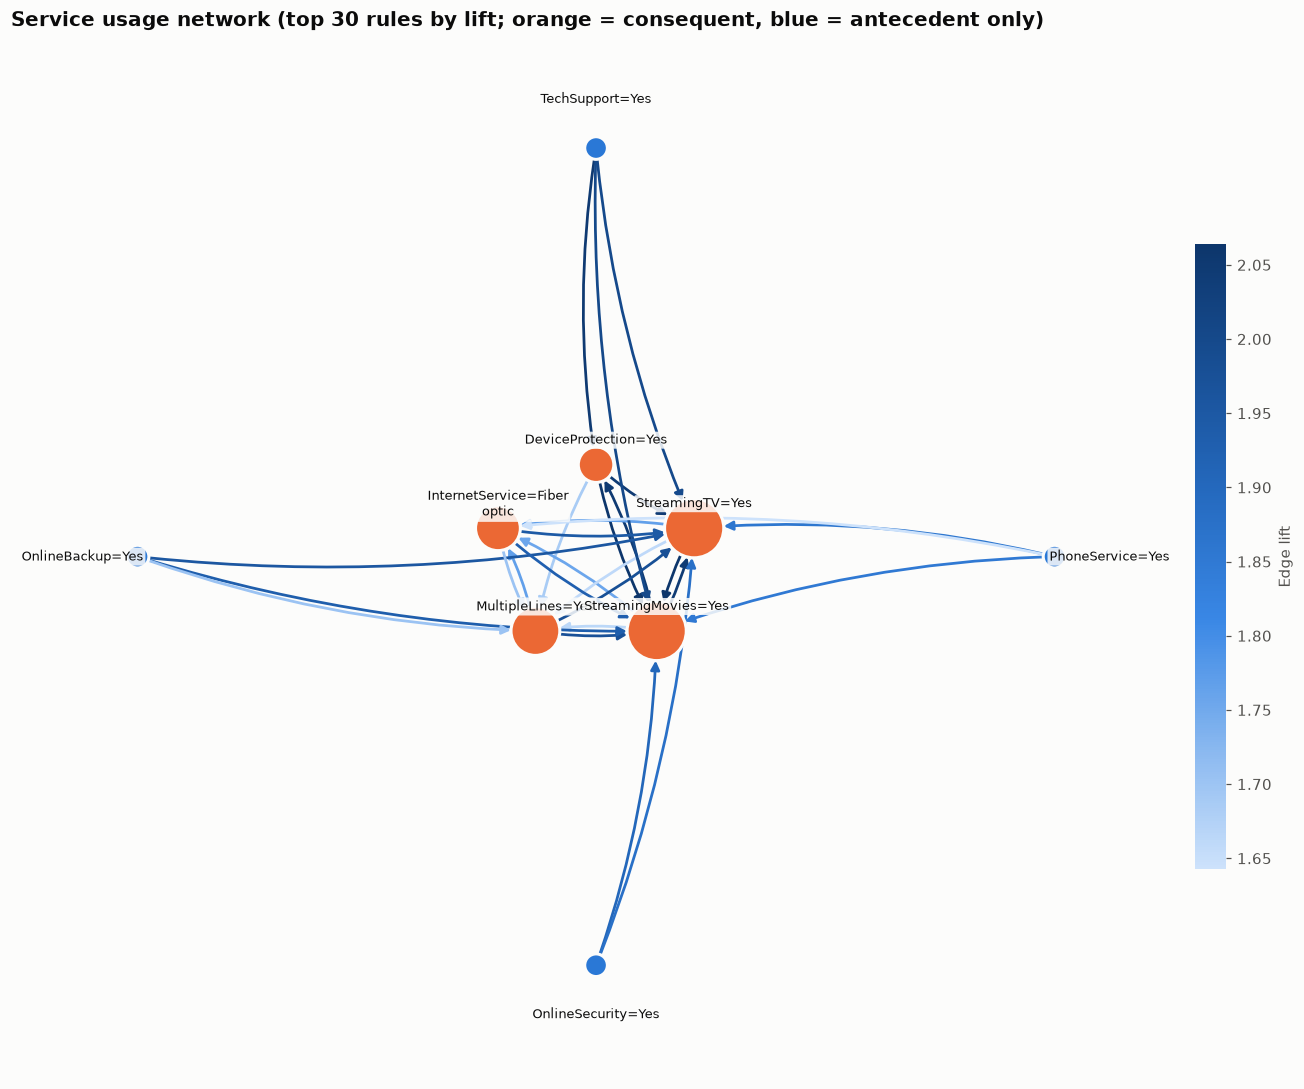

In [18]:
viz.plot_rule_network(service_rules[service_rules["antecedent_len"] <= 2], title="Service usage network");

## 7. Luật gắn với rời mạng (`→ Churn=Yes`)

Apriori có mục tiêu khai phá trên tập khách có nhãn đích với ngưỡng cục bộ `min_support / P(nhãn đích)`. Support của luật vẫn được tính trên toàn bộ dữ liệu; mẫu số confidence là số khách khớp vế trái trên toàn bộ dữ liệu.

Luật được tỉa nếu confidence không tăng quá `min_improvement` so với luật con tổng quát hơn. Các luật mô tả mối liên hệ, không chứng minh nguyên nhân rời mạng.


In [19]:
churn_rules = result.churn_rules
print(f"{len(churn_rules):,} non-redundant churn rules | params: {settings.churn}")
analysis.readable_rules(churn_rules).head(15)

692 non-redundant churn rules | params: TargetParams(target='Churn=Yes', min_support=0.03, min_confidence=0.55, min_lift=2.0, max_len=5, min_improvement=0.02)


,rule,antecedents,consequents,antecedent_len,support,confidence,lift,leverage,conviction
0,"{Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}","Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m",Churn=Yes,4,0.0330,0.7891,2.9690,0.0219,3.4816
1,"{MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0310,0.7730,2.9086,0.0203,3.2351
2,"{InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0316,0.7708,2.9002,0.0207,3.2038
3,"{MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}","MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0334,0.7680,2.8895,0.0219,3.1644
4,"{InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0368,0.7640,2.8745,0.0240,3.1112
5,"{InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0407,0.7586,2.8543,0.0264,3.0417
6,"{MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}","MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m",Churn=Yes,4,0.0350,0.7523,2.8305,0.0226,2.9641
7,"{InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m} → {Churn=Yes}","InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m",Churn=Yes,3,0.0356,0.7508,2.8247,0.0230,2.9457
8,"{InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low} → {Churn=Yes}","InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low",Churn=Yes,3,0.0593,0.7487,2.8168,0.0382,2.9211
9,"{MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}","MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m",Churn=Yes,4,0.0348,0.7470,2.8104,0.0224,2.9015


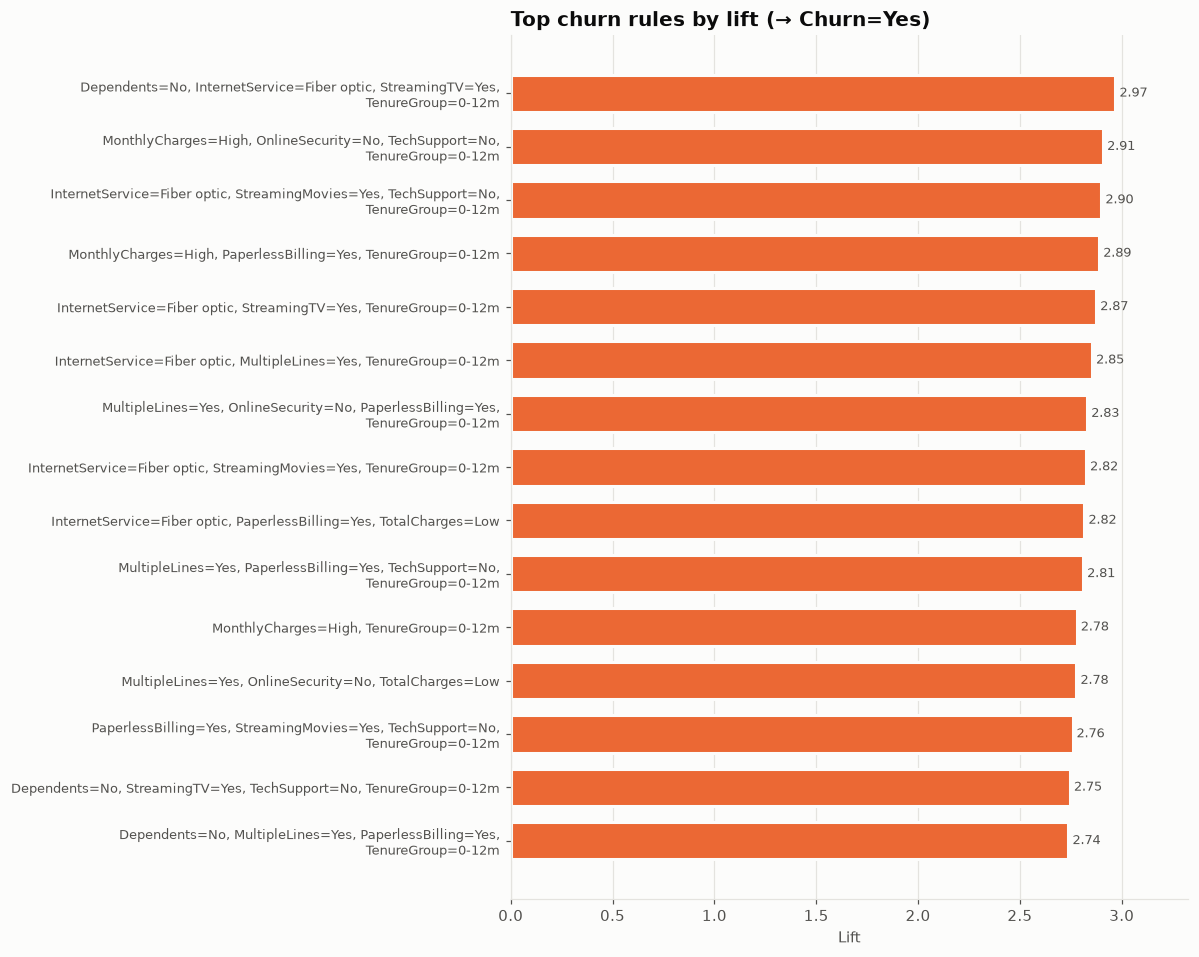

In [20]:
viz.plot_top_rules(churn_rules, title="Top churn rules by lift (→ Churn=Yes)",
                   color=viz.SERIES[1], show_consequent=False);

In [21]:
analysis.readable_rules(churn_rules.nlargest(10, "support"))[["rule", "support", "confidence", "lift"]]

,rule,support,confidence,lift
0,"{Contract=Month-to-month, InternetService=Fiber optic, TechSupport=No} → {Churn=Yes}",0.1469,0.5752,2.1640
1,"{Contract=Month-to-month, InternetService=Fiber optic, OnlineSecurity=No} → {Churn=Yes}",0.1466,0.5812,2.1866
2,"{InternetService=Fiber optic, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1381,0.5501,2.0699
3,"{Contract=Month-to-month, InternetService=Fiber optic, PaperlessBilling=Yes} → {Churn=Yes}",0.1368,0.5696,2.1430
4,"{Contract=Month-to-month, OnlineSecurity=No, PaperlessBilling=Yes, TechSupport=No} → {Churn=Yes}",0.1340,0.5836,2.1959
5,"{Contract=Month-to-month, Dependents=No, PaperlessBilling=Yes, TechSupport=No} → {Churn=Yes}",0.1317,0.5657,2.1283
6,"{Contract=Month-to-month, InternetService=Fiber optic, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1315,0.6070,2.2836
7,"{Contract=Month-to-month, Dependents=No, OnlineSecurity=No, PaperlessBilling=Yes} → {Churn=Yes}",0.1314,0.5676,2.1354
8,"{Contract=Month-to-month, OnlineBackup=No, OnlineSecurity=No, TechSupport=No} → {Churn=Yes}",0.1273,0.5759,2.1669
9,"{Contract=Month-to-month, PaymentMethod=Electronic check, TechSupport=No} → {Churn=Yes}",0.1249,0.5842,2.1979


### 7.1. Độ phủ thực tế của các luật churn trên tập khách hàng

In [22]:
coverage = analysis.rule_coverage(churn_rules, result.onehot, settings.churn.target, top_n=15)
coverage.style.format({"target_rate": "{:.1%}", "cumulative_recall": "{:.1%}"}).hide(axis="index")

rule,customers,target_hits,target_rate,cumulative_recall
"{Dependents=No, InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}",294,232,78.9%,12.4%
"{MonthlyCharges=High, OnlineSecurity=No, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",282,218,77.3%,15.9%
"{InternetService=Fiber optic, StreamingMovies=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",288,222,77.1%,18.3%
"{MonthlyCharges=High, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}",306,235,76.8%,19.1%
"{InternetService=Fiber optic, StreamingTV=Yes, TenureGroup=0-12m} → {Churn=Yes}",339,259,76.4%,19.4%
"{InternetService=Fiber optic, MultipleLines=Yes, TenureGroup=0-12m} → {Churn=Yes}",377,286,75.9%,25.2%
"{MultipleLines=Yes, OnlineSecurity=No, PaperlessBilling=Yes, TenureGroup=0-12m} → {Churn=Yes}",327,246,75.2%,26.0%
"{InternetService=Fiber optic, StreamingMovies=Yes, TenureGroup=0-12m} → {Churn=Yes}",333,250,75.1%,26.1%
"{InternetService=Fiber optic, PaperlessBilling=Yes, TotalCharges=Low} → {Churn=Yes}",557,417,74.9%,32.5%
"{MultipleLines=Yes, PaperlessBilling=Yes, TechSupport=No, TenureGroup=0-12m} → {Churn=Yes}",328,245,74.7%,32.5%


In [23]:
analysis.item_frequency_in_rules(churn_rules).head(15).to_frame()

,rule_count
antecedents,
PaymentMethod=Electronic check,239
Contract=Month-to-month,239
TechSupport=No,212
OnlineSecurity=No,208
PaperlessBilling=Yes,207
OnlineBackup=No,184
InternetService=Fiber optic,162
Partner=No,145
DeviceProtection=No,132


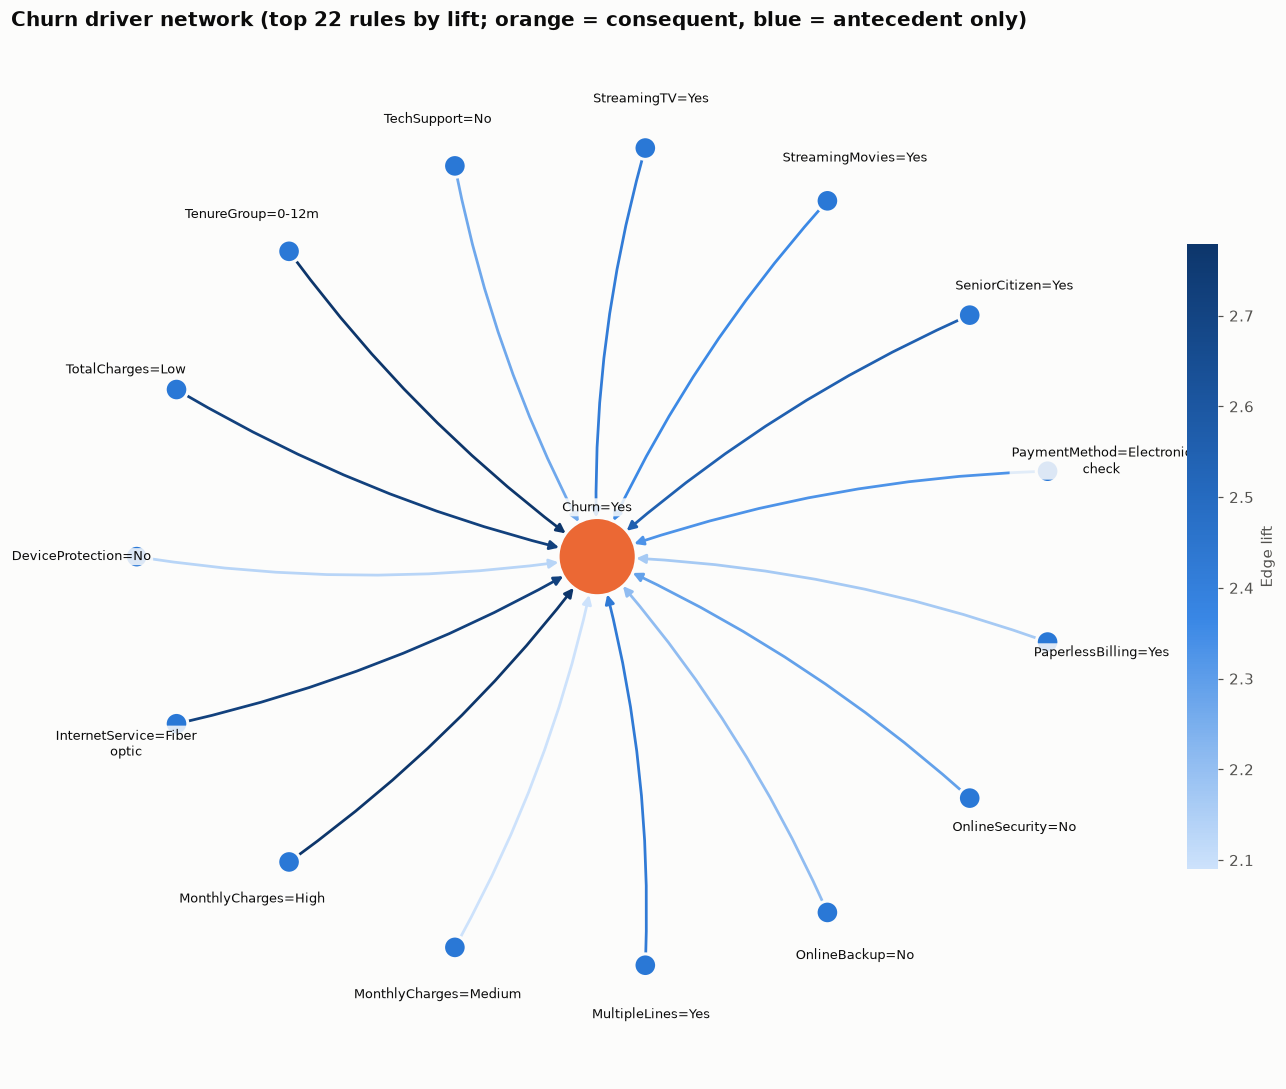

In [24]:
viz.plot_rule_network(churn_rules[churn_rules["antecedent_len"] <= 2], title="Churn driver network");

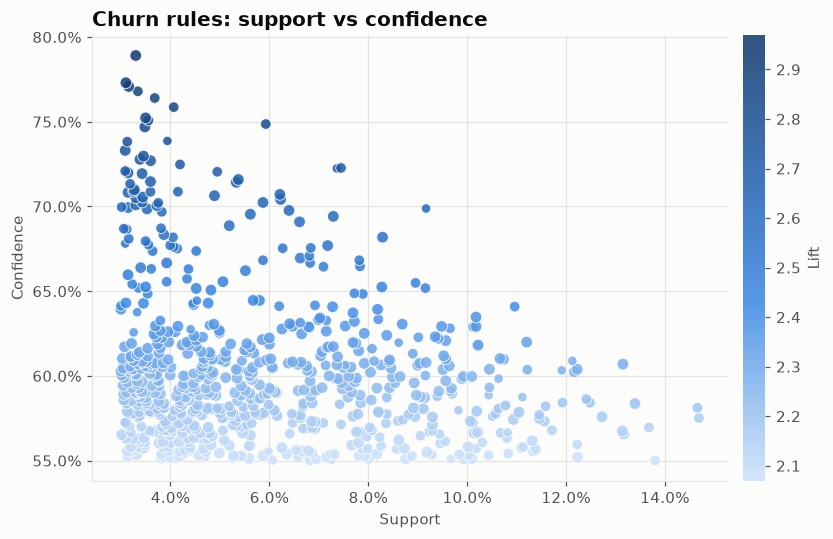

In [25]:
viz.plot_rules_scatter(churn_rules, title="Churn rules: support vs confidence");

## 8. Luật gắn với khách hàng ở lại (`→ Churn=No`)


In [26]:
retention_rules = result.retention_rules
print(f"{len(retention_rules):,} retention rules | params: {settings.retention}")
analysis.readable_rules(retention_rules)[["rule", "support", "confidence", "lift", "conviction"]]

24 retention rules | params: TargetParams(target='Churn=No', min_support=0.1, min_confidence=0.9, min_lift=1.2, max_len=5, min_improvement=0.02)


,rule,support,confidence,lift,conviction
0,"{MonthlyCharges=Low, PhoneService=Yes, TotalCharges=Medium} → {Churn=No}",0.1025,0.9743,1.3270,10.3516
1,{Contract=Two year} → {Churn=No},0.2328,0.9715,1.3232,9.3302
2,"{InternetService=No, Partner=Yes} → {Churn=No}",0.1001,0.9604,1.3081,6.7179
3,"{InternetService=DSL, TenureGroup=49-72m} → {Churn=No}",0.1072,0.9569,1.3032,6.1600
4,"{InternetService=DSL, TotalCharges=High} → {Churn=No}",0.1113,0.9549,1.3005,5.8904
5,"{MonthlyCharges=Low, TotalCharges=Medium} → {Churn=No}",0.1288,0.9447,1.2867,4.8092
6,"{PaperlessBilling=No, TenureGroup=49-72m} → {Churn=No}",0.1212,0.9446,1.2865,4.7948
7,"{Dependents=Yes, TenureGroup=49-72m} → {Churn=No}",0.1139,0.9390,1.2790,4.3599
8,"{MonthlyCharges=Low, Partner=Yes, PhoneService=Yes} → {Churn=No}",0.1091,0.9377,1.2771,4.2630
9,"{TechSupport=Yes, TenureGroup=49-72m} → {Churn=No}",0.1399,0.9345,1.2728,4.0561


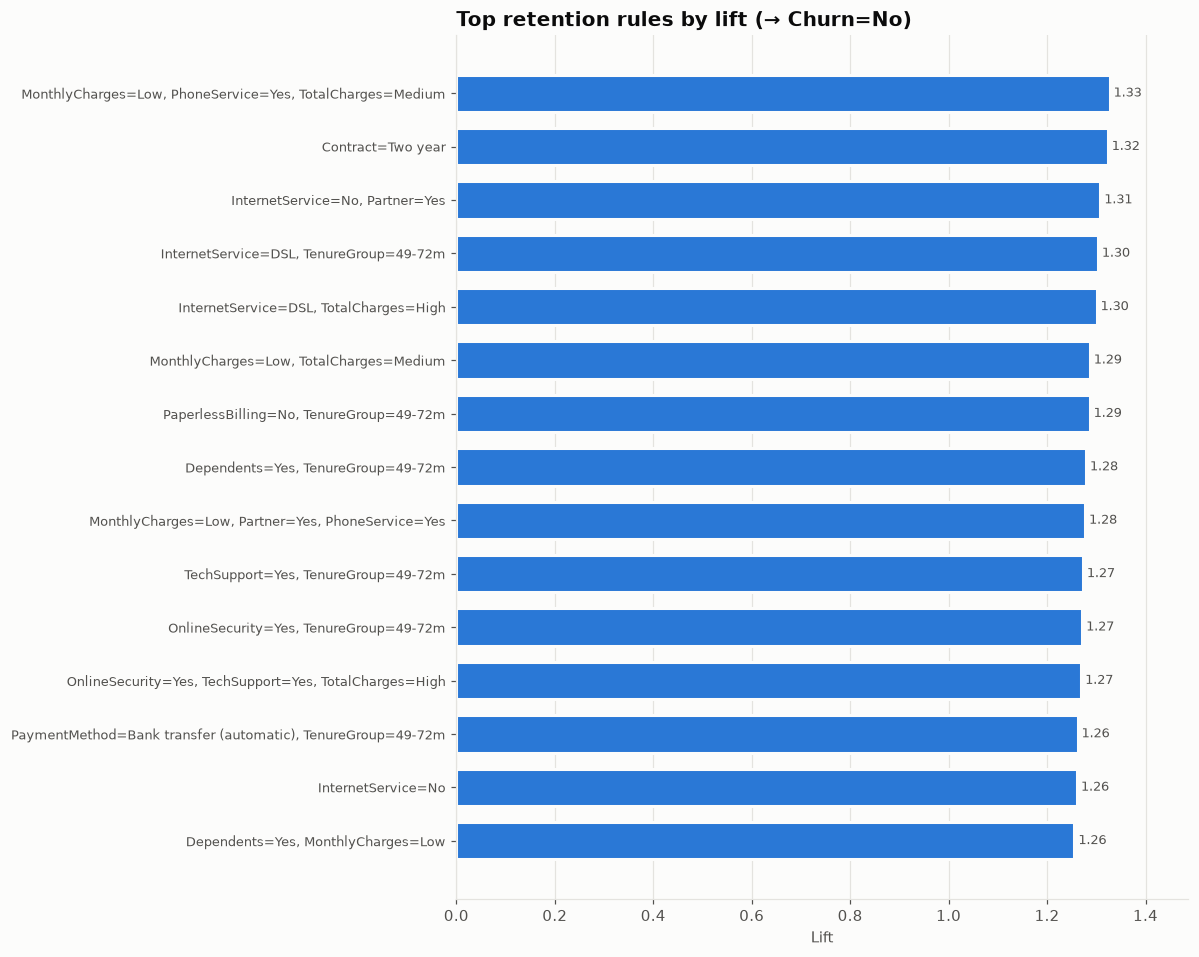

In [27]:
viz.plot_top_rules(retention_rules, title="Top retention rules by lift (→ Churn=No)", show_consequent=False);

## 9. Trả lời 6 câu hỏi

Báo cáo dưới đây được sinh trực tiếp từ các bảng kết quả của lần chạy hiện tại.


In [28]:
from IPython.display import Markdown
from telco_arm.reporting import render_report

display(Markdown(render_report(result, top=5)))


# Trả lời 6 câu hỏi khai phá luật kết hợp dịch vụ viễn thông

Dữ liệu: 7,043 bản ghi ban đầu; loại 11 bản ghi thiếu TotalCharges và 0 mã khách trùng. Phân tích **7,032 khách hàng**, trong đó **1,869 rời mạng (26.58%)** và **5,163 ở lại (73.42%)**.

Mỗi khách hàng là một giao dịch. Support = số khách có cả vế trái và vế phải / số khách toàn bộ; confidence = số khách có cả hai / số khách khớp vế trái; lift = confidence / tỷ lệ vế phải trên toàn bộ. Confidence phản ánh tỷ lệ quan sát trong dữ liệu này, không phải xác suất mua thêm trong tương lai. Luật rời mạng và ở lại mô tả mối liên hệ, không chứng minh quan hệ nhân quả hay hiệu quả can thiệp.

## Câu 1. Những dịch vụ nào thường được khách hàng đăng ký cùng nhau?

Có **141 tổ hợp từ 2 dịch vụ** với support ≥ 10%, xét tối đa 4 dịch vụ. Chỉ gồm dịch vụ có đăng ký; nhân khẩu học, hợp đồng, thanh toán và nhãn Churn không tham gia phần này. Các tổ hợp dưới đây được xếp theo support.

| Tổ hợp dịch vụ | Số khách | Support |
| --- | --- | --- |
| Internet Fiber optic + điện thoại | 3096 | 44.03% |
| nhiều đường dây + điện thoại | 2967 | 42.19% |
| điện thoại + phim trực tuyến | 2433 | 34.60% |
| điện thoại + truyền hình trực tuyến | 2420 | 34.41% |
| sao lưu trực tuyến + điện thoại | 2139 | 30.42% |

Điện thoại xuất hiện trong nhiều tổ hợp vì có tỷ lệ sử dụng nền cao. Nhiều đường dây cần dịch vụ điện thoại nên tổ hợp này có tính điều kiện kỹ thuật. Để tìm gói bán chéo, xem thêm các tổ hợp không chứa điện thoại cơ bản:

| Tổ hợp dịch vụ | Số khách | Support |
| --- | --- | --- |
| phim trực tuyến + truyền hình trực tuyến | 1939 | 27.57% |
| Internet Fiber optic + nhiều đường dây | 1938 | 27.56% |
| Internet Fiber optic + phim trực tuyến | 1751 | 24.90% |
| Internet Fiber optic + truyền hình trực tuyến | 1750 | 24.89% |
| bảo vệ thiết bị + phim trực tuyến | 1594 | 22.67% |

Chi tiết: [q1_service_bundles.csv](tables/q1_service_bundles.csv).

## Câu 2. Khi dùng dịch vụ A, khả năng dùng thêm dịch vụ B là bao nhiêu?

Tính P(B|A) trực tiếp cho mọi cặp dịch vụ thuộc hai thuộc tính khác nhau. Bảng dưới xếp theo lift, bao gồm cả các liên hệ có confidence thấp hơn ngưỡng chọn luật. Hai chiều A → B và B → A có thể có confidence khác nhau.

| Dịch vụ A | Dịch vụ B | Cùng dùng / dùng A | P(B|A) | P(B) | Lift | Đạt ngưỡng luật |
| --- | --- | --- | --- | --- | --- | --- |
| bảo mật trực tuyến | hỗ trợ kỹ thuật | 1096 / 2015 | 54.39% | 29.01% | 1.87 | Không |
| hỗ trợ kỹ thuật | bảo mật trực tuyến | 1096 / 2040 | 53.73% | 28.65% | 1.87 | Không |
| truyền hình trực tuyến | phim trực tuyến | 1939 / 2703 | 71.74% | 38.84% | 1.85 | Có |
| phim trực tuyến | truyền hình trực tuyến | 1939 / 2731 | 71.00% | 38.44% | 1.85 | Có |
| bảo vệ thiết bị | hỗ trợ kỹ thuật | 1206 / 2418 | 49.88% | 29.01% | 1.72 | Không |

Ngưỡng chọn luật dịch vụ: support ≥ 10%, confidence ≥ 70%, lift ≥ 1.2. Cột confidence trong CSV lưu tỷ lệ từ 0 đến 1. Chi tiết: [q2_service_probabilities.csv](tables/q2_service_probabilities.csv).

## Câu 3. Tổ hợp đặc điểm nào gắn với rời mạng với độ tin cậy cao?

Có **692 luật → Churn=Yes** sau tỉa dư thừa. Support ≥ 3%, confidence ≥ 55%, lift ≥ 2; tối đa 4 đặc điểm ở vế trái. Confidence được so với mức rời mạng nền 26.58%.

| Tổ hợp đặc điểm | Khớp luật | Đúng nhãn | Support | Confidence | Lift |
| --- | --- | --- | --- | --- | --- |
| có người phụ thuộc: không + Internet Fiber optic + truyền hình trực tuyến + thâm niên: 0–12 tháng | 294 | 232 | 3.30% | 78.91% | 2.97 |
| cước tháng: cao + không có bảo mật trực tuyến + không có hỗ trợ kỹ thuật + thâm niên: 0–12 tháng | 282 | 218 | 3.10% | 77.30% | 2.91 |
| Internet Fiber optic + phim trực tuyến + không có hỗ trợ kỹ thuật + thâm niên: 0–12 tháng | 288 | 222 | 3.16% | 77.08% | 2.90 |
| cước tháng: cao + hóa đơn điện tử: có + thâm niên: 0–12 tháng | 306 | 235 | 3.34% | 76.80% | 2.89 |
| Internet Fiber optic + truyền hình trực tuyến + thâm niên: 0–12 tháng | 339 | 259 | 3.68% | 76.40% | 2.87 |

Ưu tiên khảo sát chất lượng dịch vụ và hỗ trợ sớm cho nhóm khớp các luật rủi ro. Luật có thể chồng lấn; không cộng số khách giữa các dòng. Độ phủ hợp của các luật nằm trong churn_rule_coverage.csv. Chi tiết: [q3_churn_patterns.csv](tables/q3_churn_patterns.csv).

## Câu 4. Tổ hợp đặc điểm nào gắn với khách hàng ở lại?

Có **24 luật → Churn=No** sau tỉa dư thừa. Support ≥ 10%, confidence ≥ 90%, lift ≥ 1.2. Mức ở lại nền là 73.42%.

| Tổ hợp đặc điểm | Khớp luật | Đúng nhãn | Support | Confidence | Lift |
| --- | --- | --- | --- | --- | --- |
| cước tháng: thấp + điện thoại + tổng cước: trung bình | 740 | 721 | 10.25% | 97.43% | 1.33 |
| hợp đồng: 2 năm | 1685 | 1637 | 23.28% | 97.15% | 1.32 |
| không dùng Internet + có bạn đời: có | 733 | 704 | 10.01% | 96.04% | 1.31 |
| Internet DSL + thâm niên: 49–72 tháng | 788 | 754 | 10.72% | 95.69% | 1.30 |
| Internet DSL + tổng cước: cao | 820 | 783 | 11.13% | 95.49% | 1.30 |

Có thể thiết kế thử nghiệm ưu đãi hợp đồng dài hạn và gói hỗ trợ phù hợp. Dữ liệu hiện tại chưa chứng minh việc chuyển hợp đồng hay thêm dịch vụ sẽ làm giảm churn. Chi tiết: [q4_retention_patterns.csv](tables/q4_retention_patterns.csv).

## Câu 5. Nhóm khách hàng theo nhân khẩu học thường chọn gói dịch vụ nào?

Xét giới tính, cao tuổi, có bạn đời và người phụ thuộc, tối đa 2 đặc điểm một nhóm. Mỗi nhóm có ít nhất 100 khách; gói gồm 2–3 dịch vụ, support toàn bộ ≥ 2%, tỷ lệ dùng trong nhóm ≥ 20%. Điện thoại cơ bản được loại khỏi gói ở câu này để thấy lựa chọn dịch vụ rõ hơn. Tên gói là tổ hợp dịch vụ quan sát được, không phải danh mục gói thương mại có sẵn.

Tổ hợp phổ biến nhất cho từng nhóm một đặc điểm:

| Nhóm | Tổ hợp dịch vụ | Dùng gói / số khách nhóm | Tỷ lệ trong nhóm | Toàn bộ dữ liệu | Lift |
| --- | --- | --- | --- | --- | --- |
| có người phụ thuộc: không | Internet Fiber optic + nhiều đường dây | 1512 / 4933 | 30.65% | 27.56% | 1.11 |
| có người phụ thuộc: có | phim trực tuyến + truyền hình trực tuyến | 554 / 2099 | 26.39% | 27.57% | 0.96 |
| có bạn đời: không | Internet Fiber optic + nhiều đường dây | 897 / 3639 | 24.65% | 27.56% | 0.89 |
| có bạn đời: có | phim trực tuyến + truyền hình trực tuyến | 1134 / 3393 | 33.42% | 27.57% | 1.21 |
| cao tuổi: không | phim trực tuyến + truyền hình trực tuyến | 1513 / 5890 | 25.69% | 27.57% | 0.93 |
| cao tuổi: có | Internet Fiber optic + nhiều đường dây | 568 / 1142 | 49.74% | 27.56% | 1.80 |
| giới tính: nữ | phim trực tuyến + truyền hình trực tuyến | 974 / 3483 | 27.96% | 27.57% | 1.01 |
| giới tính: nam | Internet Fiber optic + nhiều đường dây | 974 / 3549 | 27.44% | 27.56% | 1.00 |

Các tổ hợp nhóm và dịch vụ khác biệt nhất so với toàn bộ dữ liệu (xếp theo lift):

| Nhóm | Tổ hợp dịch vụ | Dùng gói / số khách nhóm | Tỷ lệ trong nhóm | Toàn bộ dữ liệu | Lift |
| --- | --- | --- | --- | --- | --- |
| có bạn đời: có + cao tuổi: có | Internet Fiber optic + nhiều đường dây + phim trực tuyến | 216 / 573 | 37.70% | 17.48% | 2.16 |
| có bạn đời: có + cao tuổi: có | bảo vệ thiết bị + Internet Fiber optic + nhiều đường dây | 168 / 573 | 29.32% | 13.72% | 2.14 |
| có bạn đời: có + cao tuổi: có | Internet Fiber optic + sao lưu trực tuyến + phim trực tuyến | 148 / 573 | 25.83% | 12.51% | 2.06 |
| có bạn đời: có + cao tuổi: có | Internet Fiber optic + nhiều đường dây + sao lưu trực tuyến | 162 / 573 | 28.27% | 13.72% | 2.06 |
| có bạn đời: có + cao tuổi: có | Internet Fiber optic + nhiều đường dây + truyền hình trực tuyến | 204 / 573 | 35.60% | 17.43% | 2.04 |

Các nhóm có thể giao nhau. Chọn gói theo nhu cầu và điều kiện dịch vụ thực tế; nhân khẩu học chỉ dùng để mô tả nhóm. Chi tiết: [q5_demographic_bundles.csv](tables/q5_demographic_bundles.csv).

## Câu 6. Có thể xây dựng gợi ý nâng cấp gói từ các luật tìm được không?

Có. **74 luật có khách đủ điều kiện** tạo **3,005 gợi ý** cho **2,062 khách** trong 5,163 khách Churn=No. Mỗi khách nhận tối đa 3 dịch vụ bổ sung khác nhau.

Chỉ dùng các dịch vụ đã đăng ký ở vế trái và một dịch vụ bổ sung ở vế phải; khách chưa có dịch vụ được gợi ý, có Internet nếu là tiện ích Internet hoặc có điện thoại nếu thêm nhiều đường dây. Xếp hạng theo lift, confidence, support rồi ưu tiên luật ngắn khi hòa điểm. Churn=No chỉ xác định nhóm minh họa còn ở lại; không dùng làm điều kiện dự đoán mua thêm.

| Luật gợi ý | Confidence | Lift | Khách đủ điều kiện | Được chọn theo luật |
| --- | --- | --- | --- | --- |
| phim trực tuyến + truyền hình trực tuyến + hỗ trợ kỹ thuật → bảo vệ thiết bị | 74.68% | 2.17 | 183 | 183 |
| bảo vệ thiết bị + truyền hình trực tuyến + hỗ trợ kỹ thuật → phim trực tuyến | 83.83% | 2.16 | 124 | 124 |
| bảo vệ thiết bị + nhiều đường dây + phim trực tuyến → truyền hình trực tuyến | 82.91% | 2.16 | 138 | 138 |
| bảo vệ thiết bị + Internet Fiber optic + phim trực tuyến → truyền hình trực tuyến | 82.83% | 2.15 | 123 | 46 |
| bảo vệ thiết bị + nhiều đường dây + truyền hình trực tuyến → phim trực tuyến | 83.50% | 2.15 | 131 | 71 |

Ví dụ gợi ý theo khách hàng:

| Mã khách | Hạng | Dịch vụ nên giới thiệu | Căn cứ | Luật |
| --- | --- | --- | --- | --- |
| 0002-ORFBO | 1 | phim trực tuyến | điện thoại + truyền hình trực tuyến + hỗ trợ kỹ thuật | UP0019 |
| 0002-ORFBO | 2 | nhiều đường dây | sao lưu trực tuyến + điện thoại + truyền hình trực tuyến | UP0063 |
| 0003-MKNFE | 1 | truyền hình trực tuyến | nhiều đường dây + phim trực tuyến | UP0025 |
| 0013-MHZWF | 1 | bảo vệ thiết bị | phim trực tuyến + truyền hình trực tuyến + hỗ trợ kỹ thuật | UP0001 |
| 0013-SMEOE | 1 | nhiều đường dây | bảo vệ thiết bị + Internet Fiber optic + truyền hình trực tuyến | UP0059 |

Đây là gợi ý bán chéo dịch vụ dựa trên đồng sử dụng, chưa xác định gói giá cao hơn, doanh thu tăng thêm hay xác suất chấp nhận ưu đãi. Cần dữ liệu giá gói, lịch sử mua và thử nghiệm A/B để đánh giá chuyển đổi và giữ chân. Chi tiết: [q6_upgrade_rules.csv](tables/q6_upgrade_rules.csv), [q6_customer_recommendations.csv](tables/q6_customer_recommendations.csv).

## Cách đọc và tái lập kết quả

Chạy `python main.py` từ thư mục dự án. `--top` chỉ thay đổi số dòng trình bày; CSV luôn chứa toàn bộ kết quả thỏa điều kiện. `--no-figures` bỏ bước tạo biểu đồ. Các tham số, dấu vân tay SHA-256 của dữ liệu, ngưỡng chia nhóm cước và số lượng đầu ra được lưu trong [run_metadata.json](run_metadata.json).

MonthlyCharges và TotalCharges được chia ba phân vị trên dữ liệu đã làm sạch; thâm niên chia 0–12, 13–24, 25–48, 49–72 tháng. Tỉa luật churn/ở lại giữ luật có confidence cao hơn mọi luật con được xét trên cùng tập nhãn quá 2 điểm phần trăm theo cấu hình mặc định. Các tỷ lệ là mô tả trên dữ liệu dùng khai phá, chưa phải đánh giá trên tập kiểm định độc lập. Những khách mới thiếu TotalCharges đã bị loại nên kết quả không đại diện đầy đủ cho nhóm thâm niên 0 tháng.


## 10. Xuất báo cáo, bảng và biểu đồ


In [29]:
from telco_arm.reporting import export_report

tables = export_tables(result, settings.paths.tables_dir)
figures = export_figures(result, settings.paths.figures_dir)
reports = export_report(result, settings.paths.output_dir)
pd.DataFrame({'file': [p.relative_to(PROJECT_ROOT).as_posix() for p in [*reports, *tables, *figures]]})


,file
0,outputs/answers_6_questions.md
1,outputs/run_metadata.json
2,outputs/tables/item_support.csv
3,outputs/tables/frequent_itemsets.csv
4,outputs/tables/service_rules.csv
5,outputs/tables/churn_rules.csv
6,outputs/tables/retention_rules.csv
7,outputs/tables/churn_rule_coverage.csv
8,outputs/tables/churn_rate_by_feature.csv
9,outputs/tables/q1_service_bundles.csv
